# Efficient Frontier

In [25]:
# Purpose: Import the numerical, tabular, plotting, and scientific-computing tools used throughout the analysis.
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import scipy

In [26]:
# Purpose: Load monthly industry returns and convert percentage values and date labels into analysis-ready formats.
ind=pd.read_csv("data/ind30_m_vw_rets.csv",header=0,index_col=0)/100
ind.index=pd.to_datetime(ind.index,format="%Y%m").to_period("M")

### Data Preprocessing

In [27]:
ind.head()

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
1926-07,0.0056,-0.0519,0.0129,0.0293,0.1097,-0.0048,0.0808,0.0177,0.0814,0.0039,...,0.0083,0.0922,0.0206,0.0770,0.0193,-0.2379,0.0007,0.0187,0.0037,0.0520
1926-08,0.0259,0.2703,0.0650,0.0055,0.1001,-0.0358,-0.0251,0.0425,0.0550,0.0814,...,0.0217,0.0202,0.0439,-0.0238,0.0488,0.0539,-0.0075,-0.0013,0.0446,0.0676
1926-09,0.0116,0.0402,0.0126,0.0658,-0.0099,0.0073,-0.0051,0.0069,0.0533,0.0231,...,0.0241,0.0225,0.0019,-0.0554,0.0005,-0.0787,0.0025,-0.0056,-0.0123,-0.0386
1926-10,-0.0306,-0.0331,0.0106,-0.0476,0.0947,-0.0468,0.0012,-0.0057,-0.0476,0.0100,...,-0.0011,-0.0200,-0.0109,-0.0508,-0.0264,-0.1538,-0.0220,-0.0411,-0.0516,-0.0849
1926-11,0.0635,0.0729,0.0455,0.0166,-0.0580,-0.0054,0.0187,0.0542,0.0520,0.0311,...,0.0163,0.0377,0.0364,0.0384,0.0160,0.0467,0.0652,0.0433,0.0224,0.0400


In [28]:
ind.columns
#There are unwanted spaces after column titles

Index(['Food ', 'Beer ', 'Smoke', 'Games', 'Books', 'Hshld', 'Clths', 'Hlth ',
       'Chems', 'Txtls', 'Cnstr', 'Steel', 'FabPr', 'ElcEq', 'Autos', 'Carry',
       'Mines', 'Coal ', 'Oil  ', 'Util ', 'Telcm', 'Servs', 'BusEq', 'Paper',
       'Trans', 'Whlsl', 'Rtail', 'Meals', 'Fin  ', 'Other'],
      dtype='str')

In [29]:
# Purpose: Strip trailing spaces from industry names so later column selections are reliable.
#Removing unwannted space
ind.columns=ind.columns.str.strip()
ind.columns

Index(['Food', 'Beer', 'Smoke', 'Games', 'Books', 'Hshld', 'Clths', 'Hlth',
       'Chems', 'Txtls', 'Cnstr', 'Steel', 'FabPr', 'ElcEq', 'Autos', 'Carry',
       'Mines', 'Coal', 'Oil', 'Util', 'Telcm', 'Servs', 'BusEq', 'Paper',
       'Trans', 'Whlsl', 'Rtail', 'Meals', 'Fin', 'Other'],
      dtype='str')

In [30]:
%load_ext autoreload
%autoreload 2
import risk_kit as erk

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
# Purpose: Reload the reusable risk toolkit and use its prepared industry-return loader for the remaining analysis.
# Creating function for importing ind_returns data in risk kit 
ind=erk.get_ind_returns()
ind.shape

(1110, 30)

In [32]:
ind.head()

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
1926-07,0.0056,-0.0519,0.0129,0.0293,0.1097,-0.0048,0.0808,0.0177,0.0814,0.0039,...,0.0083,0.0922,0.0206,0.0770,0.0193,-0.2379,0.0007,0.0187,0.0037,0.0520
1926-08,0.0259,0.2703,0.0650,0.0055,0.1001,-0.0358,-0.0251,0.0425,0.0550,0.0814,...,0.0217,0.0202,0.0439,-0.0238,0.0488,0.0539,-0.0075,-0.0013,0.0446,0.0676
1926-09,0.0116,0.0402,0.0126,0.0658,-0.0099,0.0073,-0.0051,0.0069,0.0533,0.0231,...,0.0241,0.0225,0.0019,-0.0554,0.0005,-0.0787,0.0025,-0.0056,-0.0123,-0.0386
1926-10,-0.0306,-0.0331,0.0106,-0.0476,0.0947,-0.0468,0.0012,-0.0057,-0.0476,0.0100,...,-0.0011,-0.0200,-0.0109,-0.0508,-0.0264,-0.1538,-0.0220,-0.0411,-0.0516,-0.0849
1926-11,0.0635,0.0729,0.0455,0.0166,-0.0580,-0.0054,0.0187,0.0542,0.0520,0.0311,...,0.0163,0.0377,0.0364,0.0384,0.0160,0.0467,0.0652,0.0433,0.0224,0.0400


<Axes: >

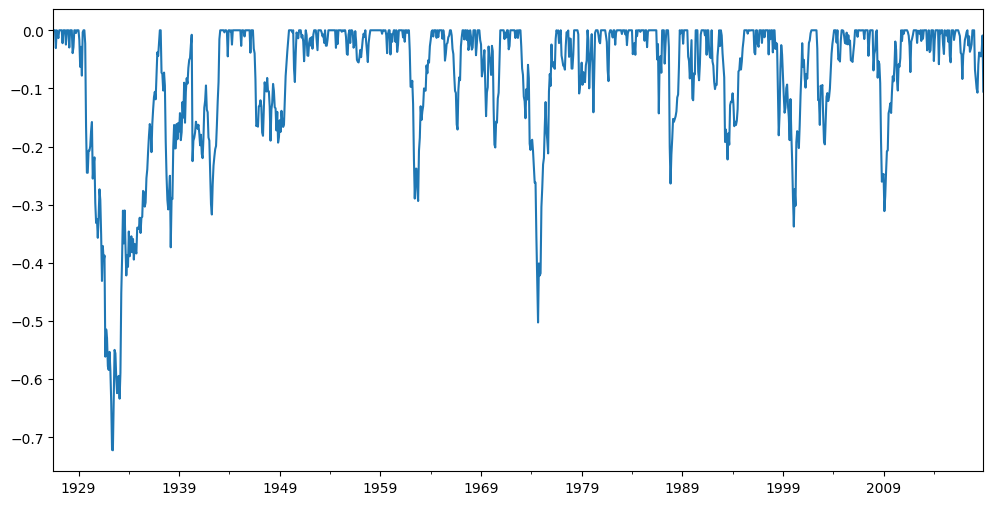

In [33]:
# Purpose: Visualise the Food industry's cumulative loss from its previous peak to understand downside risk.
erk.drawdown(ind['Food'])["Drawdown"].plot.line(figsize=(12,6))

In [34]:
# Purpose: Estimate modified Gaussian Value at Risk for every industry, incorporating skewness and kurtosis.
erk.var_gaussian(ind,modified=True).sort_values()

Beer     0.033881
Coal     0.047359
Food     0.061207
Telcm    0.064719
Hshld    0.064886
Trans    0.065468
Servs    0.066112
Autos    0.069545
Util     0.071585
Hlth     0.071884
Paper    0.073181
Steel    0.074436
Fin      0.075199
Chems    0.079262
Txtls    0.079519
Clths    0.079707
Smoke    0.080292
Rtail    0.080437
Whlsl    0.080604
Oil      0.081244
Other    0.087270
ElcEq    0.087624
FabPr    0.088491
Books    0.088675
Cnstr    0.089668
Carry    0.094527
Meals    0.098403
BusEq    0.099377
Games    0.100701
Mines    0.102782
dtype: float64

<Axes: >

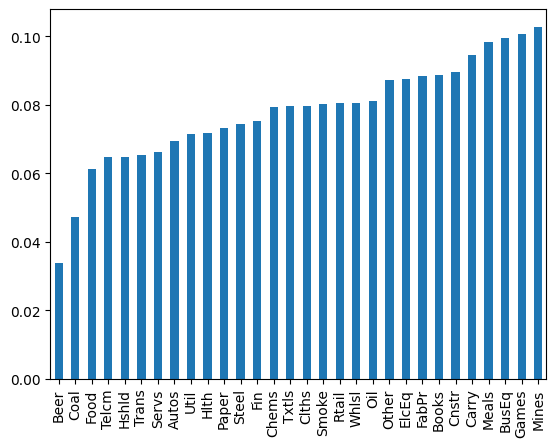

In [35]:
erk.var_gaussian(ind,modified=True).sort_values().plot.bar()

<Axes: title={'center': 'Inndustry Sharpe Ratios (2000-2018)'}>

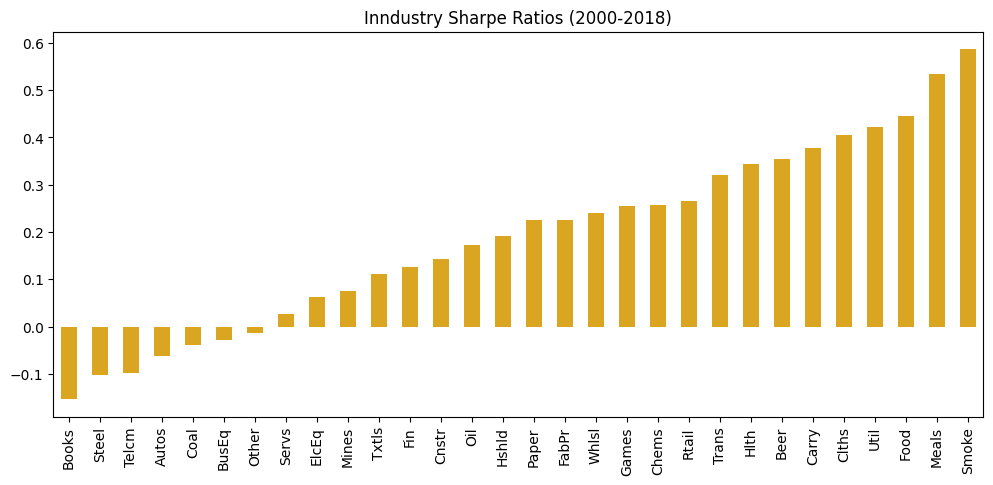

In [36]:
# Purpose: Compare risk-adjusted performance after 2000 using annualised Sharpe ratios.
erk.sharpe_ratio(ind["2000":],0.03,12).sort_values().plot.bar(title="Inndustry Sharpe Ratios (2000-2018)",figsize=(12,5),color="goldenrod")

### Forming the Efficient Frontier

In [37]:
# Purpose: Estimate annualised expected returns from the 1995–2000 historical sample used for the frontier.
#Exprected Returns
er=erk.annulize_rets(ind["1995":"2000"],12)

<Axes: >

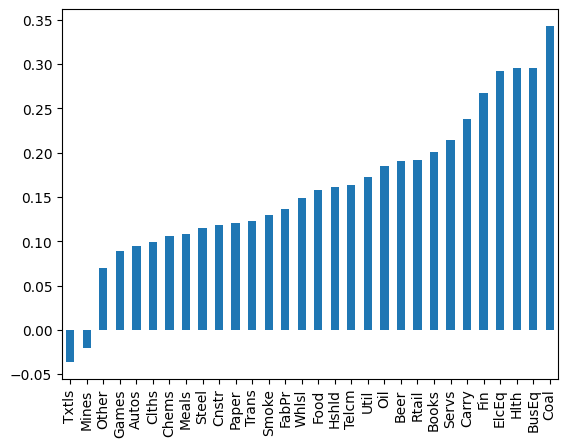

In [38]:
er.sort_values().plot.bar()

In [39]:
# Purpose: Estimate the covariance matrix, which captures how industry returns move together.
# Generating covariance matrix
cov = ind["1995":"2000"].cov()
cov

,Food,Beer,Smoke,Games,Books,Hshld,Clths,Hlth,Chems,Txtls,...,Telcm,Servs,BusEq,Paper,Trans,Whlsl,Rtail,Meals,Fin,Other
Food,0.002287,0.002077,0.001757,0.000701,0.000886,0.001208,0.001474,0.001105,0.001253,0.001021,...,0.000610,0.000211,-0.000280,0.001205,0.001312,0.000633,0.001165,0.001085,0.001839,0.000898
Beer,0.002077,0.004599,0.001143,0.001147,0.000765,0.002447,0.001415,0.001689,0.001292,0.001721,...,0.000978,0.000400,0.000028,0.001455,0.001974,0.000609,0.001442,0.001634,0.002236,0.001196
Smoke,0.001757,0.001143,0.007130,0.000296,-0.000099,0.000981,0.000761,0.000877,0.000687,0.000555,...,0.000057,-0.000266,-0.000300,0.001061,0.000241,0.001363,0.000069,0.000590,0.001117,0.001418
Games,0.000701,0.001147,0.000296,0.003271,0.001485,0.001018,0.001814,0.001219,0.001547,0.001291,...,0.001615,0.002399,0.002935,0.001615,0.001438,0.001681,0.001649,0.001383,0.002080,0.002088
Books,0.000886,0.000765,-0.000099,0.001485,0.002302,0.000876,0.002037,0.000657,0.001559,0.001362,...,0.001627,0.001996,0.001624,0.001481,0.001576,0.001205,0.001995,0.001026,0.001979,0.001283
Hshld,0.001208,0.002447,0.000981,0.001018,0.000876,0.002849,0.001046,0.001253,0.001226,0.001172,...,0.000889,0.001111,0.000906,0.001594,0.001366,0.000578,0.001157,0.001076,0.001652,0.001322
Clths,0.001474,0.001415,0.000761,0.001814,0.002037,0.001046,0.004896,0.000759,0.002547,0.002105,...,0.001263,0.001401,0.000746,0.002683,0.002466,0.001654,0.002607,0.002229,0.002699,0.001974
Hlth,0.001105,0.001689,0.000877,0.001219,0.000657,0.001253,0.000759,0.002252,0.000444,0.000538,...,0.001093,0.001390,0.001264,0.000552,0.000880,0.000907,0.000770,0.000900,0.001412,0.001099
Chems,0.001253,0.001292,0.000687,0.001547,0.001559,0.001226,0.002547,0.000444,0.002944,0.001705,...,0.000860,0.001072,0.000935,0.002581,0.001966,0.001257,0.001661,0.001425,0.002143,0.001832
Txtls,0.001021,0.001721,0.000555,0.001291,0.001362,0.001172,0.002105,0.000538,0.001705,0.002882,...,0.000790,0.000582,0.000685,0.001869,0.001760,0.001426,0.001696,0.001126,0.001789,0.001668


In [40]:
# Purpose: Define the matrix formulas for portfolio return and volatility before moving them into the shared toolkit.
### PUTTING THESE IN RISK KIT 
#Calculating Returns using matrix formula method
def portfolio_return(weights,returns):
    """
    weights --> Returns
    """
    return weights.T @ returns

#Calculating volatility using matrix formula method
def portfolio_vol(weights,covmat):
    """
    weights --> volatility
    """
    return (weights.T @ covmat @ weights)**0.5

In [41]:
# Purpose: Select four industries as a compact example for inspecting expected returns and covariance.
#Choosing sample data from set
l=["Food","Beer","Smoke","Coal"]
er[l]

Food     0.157362
Beer     0.190134
Smoke    0.129288
Coal     0.343089
dtype: float64

In [42]:
# Creating covariance matrix
cov.loc[l,l]

,Food,Beer,Smoke,Coal
Food,0.002287,0.002077,0.001757,0.000034
Beer,0.002077,0.004599,0.001143,0.001261
Smoke,0.001757,0.001143,0.007130,-0.000544
Coal,0.000034,0.001261,-0.000544,0.016153


In [43]:
# Purpose: Create a 25% allocation to each selected industry as a simple benchmark portfolio.
#giving equal weights to all columns
weights=np.repeat(1/4,4)

In [44]:
# Purpose: Calculate the benchmark portfolio's expected return with the toolkit helper.
#using functions from risk kit directly
erk.portfolio_return(er[l],weights)

np.float64(0.20496820684146116)

In [45]:
# Purpose: Calculate the benchmark portfolio's volatility from the selected-assets covariance matrix.
erk.portfolio_vol(weights,cov.loc[l,l])

np.float64(0.05100412722141178)

We calculated return and volatility in matrix format so that we can plot effecient frontier 

### 2 Asset Frontier

In [46]:
# Purpose: Choose two industries to make the efficient-frontier trade-off easy to visualise.
l=["Games","Fin"]

In [50]:
# Purpose: Sweep the allocation from 0% to 100% in the first asset to generate feasible two-asset portfolios.
#Generating linearly spaced points between min and max weight distributions
n_points=20
weights=[np.array([w,1-w]) for w in np.linspace(0,1,n_points)]

In [49]:
weights

[array([0., 1.]),
 array([0.05263158, 0.94736842]),
 array([0.10526316, 0.89473684]),
 array([0.15789474, 0.84210526]),
 array([0.21052632, 0.78947368]),
 array([0.26315789, 0.73684211]),
 array([0.31578947, 0.68421053]),
 array([0.36842105, 0.63157895]),
 array([0.42105263, 0.57894737]),
 array([0.47368421, 0.52631579]),
 array([0.52631579, 0.47368421]),
 array([0.57894737, 0.42105263]),
 array([0.63157895, 0.36842105]),
 array([0.68421053, 0.31578947]),
 array([0.73684211, 0.26315789]),
 array([0.78947368, 0.21052632]),
 array([0.84210526, 0.15789474]),
 array([0.89473684, 0.10526316]),
 array([0.94736842, 0.05263158]),
 array([1., 0.])]

<Axes: xlabel='Vol', ylabel='R'>

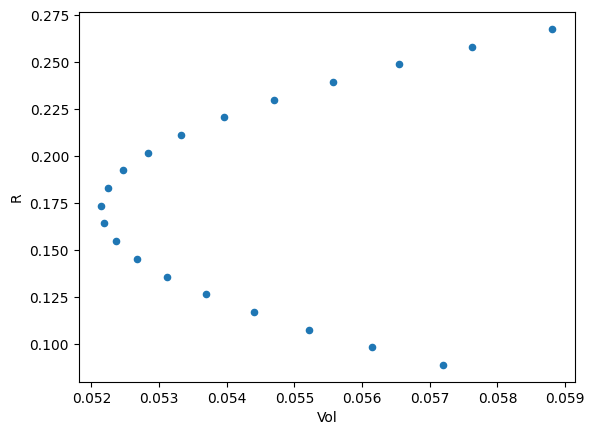

In [54]:
# Purpose: Turn each allocation's expected return and volatility into a table and scatter plot.
rets = [erk.portfolio_return(w,er[l]) for w in weights]
vols = [erk.portfolio_vol(w,cov.loc[l,l]) for w in weights]
ef = pd.DataFrame({"R":rets,"Vol":vols})
ef.plot.scatter(x="Vol",y="R")

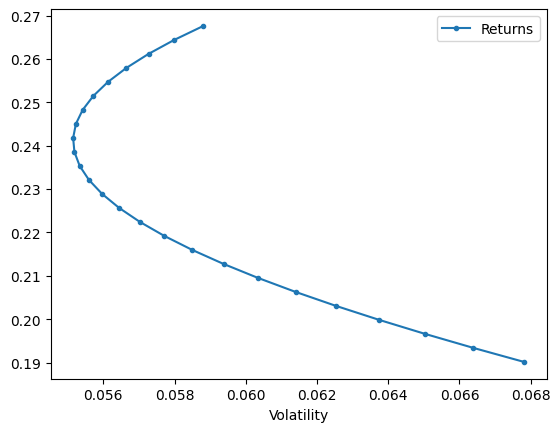

In [63]:
# Purpose: Use the reusable two-asset plotting function to draw the frontier for a second industry pair.
l=["Fin","Beer"]
erk.plot_ef2(25,er[l],cov.loc[l,l])